In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [3]:
SEASON = "2025-26"

In [6]:
players = pd.read_csv("basketball_data/player_stats_2025-26.csv")
players.head()

,PLAYER_ID,PLAYER_NAME,NICKNAME,TEAM_ID,TEAM_ABBREVIATION,AGE,GP,W,L,W_PCT,...,TS_PCT_RANK,USG_PCT_RANK,E_USG_PCT_RANK,E_PACE_RANK,PACE_RANK,sp_work_PACE_RANK,PIE_RANK,FGM_PG_RANK,FGA_PG_RANK,SEASON
0,1630639,A.J. Lawson,A.J.,1610612761,TOR,25.0,24,12,12,0.500,...,230,284,273,506,456,456,268,454,442,2025-26
1,1631260,AJ Green,AJ,1610612749,MIL,26.0,78,31,47,0.397,...,109,467,467,415,467,467,497,237,211,2025-26
2,1642358,AJ Johnson,AJ,1610612742,DAL,21.0,48,9,39,0.188,...,555,185,182,293,270,270,544,486,421,2025-26
3,203932,Aaron Gordon,Aaron,1610612743,DEN,30.0,36,27,9,0.750,...,123,133,134,394,426,426,104,101,119,2025-26
4,1628988,Aaron Holiday,Aaron,1610612745,HOU,29.0,57,38,19,0.667,...,272,350,342,451,445,445,468,402,385,2025-26


In [7]:
players["THREE_POINT_ATTEMPT_RATE"] = (
    players["FG3A"] / players["FGA"].replace(0, np.nan)
)

players["AST_TO_TOV"] = (
    players["AST"] / players["TOV"].replace(0, np.nan)
)

players["REBOUND_SHARE"] = (
    players["REB"] / players["MIN"].replace(0, np.nan)
)

features = [
    "USG_PCT",
    "TS_PCT",
    "AST",
    "TOV",
    "THREE_POINT_ATTEMPT_RATE",
    "FG3_PCT",
    "FT_PCT",
    "AST_TO_TOV",
    "REB",
    "OREB",
    "DREB",
    "STL",
    "BLK",
]

available_features = [
    col for col in features
    if col in players.columns
]

print("Available features:", available_features)

Available features: ['USG_PCT', 'TS_PCT', 'AST', 'TOV', 'THREE_POINT_ATTEMPT_RATE', 'FG3_PCT', 'FT_PCT', 'AST_TO_TOV', 'REB', 'OREB', 'DREB', 'STL', 'BLK']


C:\Users\phill\AppData\Local\Temp\ipykernel_30348\385024978.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  players["THREE_POINT_ATTEMPT_RATE"] = (
C:\Users\phill\AppData\Local\Temp\ipykernel_30348\385024978.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  players["AST_TO_TOV"] = (
C:\Users\phill\AppData\Local\Temp\ipykernel_30348\385024978.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at

In [8]:
eligible = players[
  (players['GP'] >= 20) &
  (players['MIN'] >= 10)
].copy()

print("Total player rows:", len(players))
print("Eligible player rows:", len(eligible))

Total player rows: 582
Eligible player rows: 406


In [9]:
feature_data = eligible[available_features].copy()

# Replace infinite values from division by zero.
feature_data = feature_data.replace(
    [np.inf, -np.inf],
    np.nan,
)

# Drop rows missing any selected feature for this initial prototype.
valid_mask = feature_data.notna().all(axis=1)

eligible = eligible.loc[valid_mask].copy()
feature_data = feature_data.loc[valid_mask].copy()

print("Rows available for clustering:", len(feature_data))
feature_data.head()

Rows available for clustering: 406


,USG_PCT,TS_PCT,AST,TOV,THREE_POINT_ATTEMPT_RATE,FG3_PCT,FT_PCT,AST_TO_TOV,REB,OREB,DREB,STL,BLK
1,0.135,0.627,1.9,1.0,0.898734,0.419,0.855,1.900000,2.7,0.4,2.4,0.5,0.1
3,0.213,0.620,2.7,1.1,0.396396,0.389,0.767,2.454545,5.8,1.4,4.4,0.6,0.3
4,0.159,0.578,1.1,0.7,0.681818,0.394,0.854,1.571429,1.0,0.2,0.8,0.5,0.1
5,0.190,0.554,1.9,1.4,0.543860,0.379,0.829,1.357143,4.2,1.1,3.1,0.6,0.5
6,0.194,0.538,1.7,1.2,0.512195,0.356,0.736,1.416667,3.1,0.6,2.4,0.9,0.4


In [10]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(feature_data)

print("Feature matrix shape:", X_scaled.shape)

Feature matrix shape: (406, 13)


In [11]:
from sklearn.metrics import silhouette_score

results = []

for k in range(2, 11):
  model = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=20,
  )

  labels = model.fit_predict(X_scaled)

  results.append({
    "k": k,
    "inertia": model.inertia_,
    "silhouette": silhouette_score(X_scaled, labels),
  })

cluster_evaluation = pd.DataFrame(results)

display(cluster_evaluation)

,k,inertia,silhouette
0,2,4080.432383,0.240794
1,3,3405.812731,0.235609
2,4,3139.832253,0.162703
3,5,2905.189645,0.145438
4,6,2714.449991,0.137903
5,7,2549.857142,0.152391
6,8,2413.370633,0.148498
7,9,2294.669999,0.143255
8,10,2219.762487,0.146150


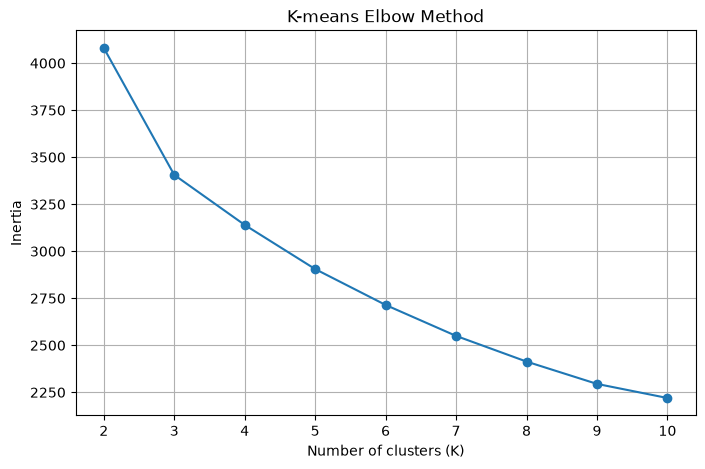

In [12]:
plt.figure(figsize=(8, 5))

plt.plot(
    cluster_evaluation["k"],
    cluster_evaluation["inertia"],
    marker="o",
)

plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("K-means Elbow Method")
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

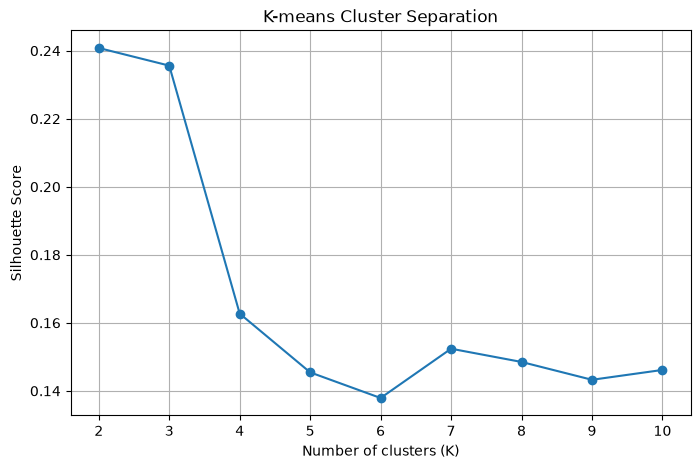

In [13]:
plt.figure(figsize=(8, 5))

plt.plot(
    cluster_evaluation["k"],
    cluster_evaluation["silhouette"],
    marker="o",
)

plt.xlabel("Number of clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("K-means Cluster Separation")
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

In [14]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=20
)

eligible["CLUSTER"] = kmeans.fit_predict(X_scaled)

cluster_profiles = eligible.groupby("CLUSTER")[available_features].mean()

display(cluster_profiles.round(3))

,USG_PCT,TS_PCT,AST,TOV,THREE_POINT_ATTEMPT_RATE,FG3_PCT,FT_PCT,AST_TO_TOV,REB,OREB,DREB,STL,BLK
CLUSTER,,,,,,,,,,,,,
0,0.166,0.562,1.889,0.953,0.515,0.353,0.768,2.035,2.959,0.740,2.218,0.686,0.300
1,0.168,0.622,1.733,1.225,0.151,0.245,0.673,1.419,7.031,2.394,4.636,0.733,0.994
2,0.247,0.582,4.695,2.289,0.375,0.349,0.816,2.085,5.198,1.047,4.158,1.119,0.505


In [15]:
kmeans7 = KMeans(
    n_clusters=7,
    random_state=42,
    n_init=20
)

eligible["CLUSTER_7"] = kmeans7.fit_predict(X_scaled)

cluster_profiles_7 = eligible.groupby("CLUSTER_7")[available_features].mean()

display(cluster_profiles_7.round(3))

,USG_PCT,TS_PCT,AST,TOV,THREE_POINT_ATTEMPT_RATE,FG3_PCT,FT_PCT,AST_TO_TOV,REB,OREB,DREB,STL,BLK
CLUSTER_7,,,,,,,,,,,,,
0,0.170,0.580,1.524,0.876,0.590,0.371,0.823,1.813,2.635,0.596,2.032,0.590,0.227
1,0.167,0.553,3.375,1.150,0.502,0.352,0.800,3.103,3.143,0.692,2.470,0.955,0.295
2,0.239,0.586,4.596,2.357,0.235,0.319,0.740,1.923,9.087,2.317,6.770,1.078,1.091
3,0.144,0.656,1.638,1.124,0.010,0.027,0.623,1.539,7.414,2.848,4.562,0.681,0.967
4,0.159,0.528,1.528,0.903,0.423,0.302,0.662,1.711,2.908,0.838,2.061,0.662,0.345
5,0.180,0.607,1.649,1.202,0.299,0.380,0.731,1.397,5.479,1.708,3.779,0.725,0.783
6,0.256,0.582,4.881,2.424,0.396,0.354,0.824,2.019,4.734,0.850,3.887,1.139,0.414
